In [ ]:
kag <- read.csv("https://drive.google.com/uc?export=download&id=1XevZuvhhQSaHRil3ZLRlnVukykDABXwq")
#head(kag)

**Summary**

I believe two distributions are well suited for classification tasks and one is not. Out of the factors, I decided to predict whether the clicks would be higher than the median: high is yes, and low is no. The decision boundary is at the median, after seeing where the 50-50 split is.

The distribution of age is the best for classification, because each level of that factor has a different distribution of yes and no. This implies that the feature is important to, or connected with, predicting yes or no.

Originally I thought the interest distribution wasn’t a great one for classification, because the waveforms were so similar. But once interest is above 60, most of the density is in the yes, with a lot of it not being in the no. So that is also a good distribution. I then plotted it as a categorical variable as well, just to make sure.

Lastly, I don’t think gender is a good distribution, because both levels have about the same split between the two classes.

In [ ]:
dim(kag)
str(kag)

[1] 1143   11

'data.frame':	1143 obs. of  11 variables:
 $ ad_id              : int  708746 708749 708771 708815 708818 708820 708889 708895 708953 708958 ...
 $ xyz_campaign_id    : int  916 916 916 916 916 916 916 916 916 916 ...
 $ fb_campaign_id     : int  103916 103917 103920 103928 103928 103929 103940 103941 103951 103952 ...
 $ age                : chr  "30-34" "30-34" "30-34" "30-34" ...
 $ gender             : chr  "M" "M" "M" "M" ...
 $ interest           : int  15 16 20 28 28 29 15 16 27 28 ...
 $ Impressions        : int  7350 17861 693 4259 4133 1915 15615 10951 2355 9502 ...
 $ Clicks             : int  1 2 0 1 1 0 3 1 1 3 ...
 $ Spent              : num  1.43 1.82 0 1.25 1.29 ...
 $ Total_Conversion   : int  2 2 1 1 1 1 1 1 1 1 ...
 $ Approved_Conversion: int  1 0 0 0 1 1 0 1 0 0 ...


In [ ]:
summary(kag)

     ad_id         xyz_campaign_id fb_campaign_id          age      
 Min.   : 708746   Min.   : 916    Min.   :103916   Length   :1143  
 1st Qu.: 777632   1st Qu.: 936    1st Qu.:115716   N.unique :   4  
 Median :1121185   Median :1178    Median :144549   N.blank  :   0  
 Mean   : 987261   Mean   :1067    Mean   :133784   Min.nchar:   5  
 3rd Qu.:1121804   3rd Qu.:1178    3rd Qu.:144658   Max.nchar:   5  
 Max.   :1314415   Max.   :1178    Max.   :179982                   
       gender        interest       Impressions          Clicks      
 Length   :1143   Min.   :  2.00   Min.   :     87   Min.   :  0.00  
 N.unique :   2   1st Qu.: 16.00   1st Qu.:   6504   1st Qu.:  1.00  
 N.blank  :   0   Median : 25.00   Median :  51509   Median :  8.00  
 Min.nchar:   1   Mean   : 32.77   Mean   : 186732   Mean   : 33.39  
 Max.nchar:   1   3rd Qu.: 31.00   3rd Qu.: 221769   3rd Qu.: 37.50  
                  Max.   :114.00   Max.   :3052003   Max.   :421.00  
     Spent        Total_Con

In [ ]:
colSums(is.na(kag))

ad_id     xyz_campaign_id      fb_campaign_id                 age 
                  0                   0                   0                   0 
             gender            interest         Impressions              Clicks 
                  0                   0                   0                   0 
              Spent    Total_Conversion Approved_Conversion 
                  0                   0                   0

In [ ]:
table(kag$gender)
table(kag$age)


  F   M 
551 592 


30-34 35-39 40-44 45-49 
  426   248   210   259 

In [ ]:
length(unique(kag$xyz_campaign_id))
table(kag$xyz_campaign_id)
length(unique(kag$Clicks))
table(kag$Clicks)

[1] 3


 916  936 1178 
  54  464  625 

[1] 183


  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19 
207 119  70  51  34  34  18  29  14  17  16  16  14  12  10  11  12   4   8  10 
 20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36  37  38  39 
 16   9   8  13  14  13   9   5  11   3   9   6   4   8   6   9   4   4   8   4 
 40  41  42  43  44  45  46  47  48  49  50  51  52  53  54  55  56  57  58  59 
  4   4   4  10   1   1   4   2   4   5   5   5   3   5   2   5   4   3   2   2 
 60  61  62  63  64  65  66  67  68  69  70  71  72  73  75  76  77  78  79  80 
  3   2   1   5   1   2   3   1   3   3   1   2   3   1   3   2   4   1   1   4 
 81  82  83  84  85  86  88  89  90  91  95  96  97  98 100 101 103 105 107 109 
  5   2   2   3   2   4   2   2   1   3   1   1   2   1   2   2   1   1   2   1 
110 111 113 114 116 117 118 119 120 123 124 125 127 128 129 130 131 134 135 136 
  1   1   2   4   1   2   1   1   4   2   1   3   1   2   1   1   1   1   3   1 
137 138 139 141 142 145 146

In [ ]:
kag$age <- factor(kag$age)
kag$gender <- factor(kag$gender)
kag$xyz_campaign_id <- factor(kag$xyz_campaign_id)

In [ ]:
num_cols <- c("Impressions", "Clicks", "Spent", "interest",
              "Total_Conversion", "Approved_Conversion")
round(cor(kag[, num_cols]), 2)

,Impressions,Clicks,Spent,interest,Total_Conversion,Approved_Conversion
Impressions,1.00,0.95,0.97,0.10,0.81,0.68
Clicks,0.95,1.00,0.99,0.09,0.69,0.56
Spent,0.97,0.99,1.00,0.07,0.73,0.59
interest,0.10,0.09,0.07,1.00,0.12,0.06
Total_Conversion,0.81,0.69,0.73,0.12,1.00,0.86
Approved_Conversion,0.68,0.56,0.59,0.06,0.86,1.00


In [ ]:
med <- median(kag$Clicks)
cuts <- med + c(-4, -2, 0, 2, 4)
for (cut in cuts) {
  cat("Clicks >", cut, ":", round(mean(kag$Clicks > cut), 2), "\n")
}

Clicks > 4 : 0.58 
Clicks > 6 : 0.53 
Clicks > 8 : 0.5 
Clicks > 10 : 0.47 
Clicks > 12 : 0.44 


In [ ]:
library(ggplot2)


In [ ]:
cutoff <- 8
kag$HighClicks <- factor(ifelse(kag$Clicks > cutoff, "Yes", "No"))
table(kag$HighClicks)

kag$interest_f <- factor(kag$interest)


 No Yes 
576 567 

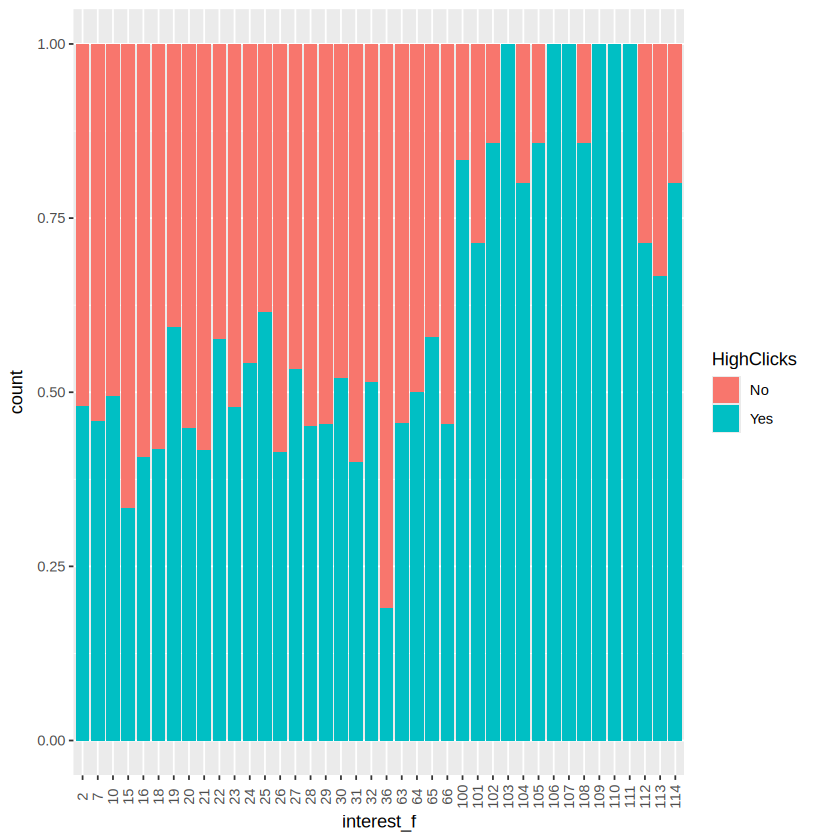

In [ ]:
ggplot(kag, aes(x = interest_f, fill = HighClicks)) +
  geom_bar(position = "fill") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

In [ ]:
predictors <- c("age", "gender", "interest")

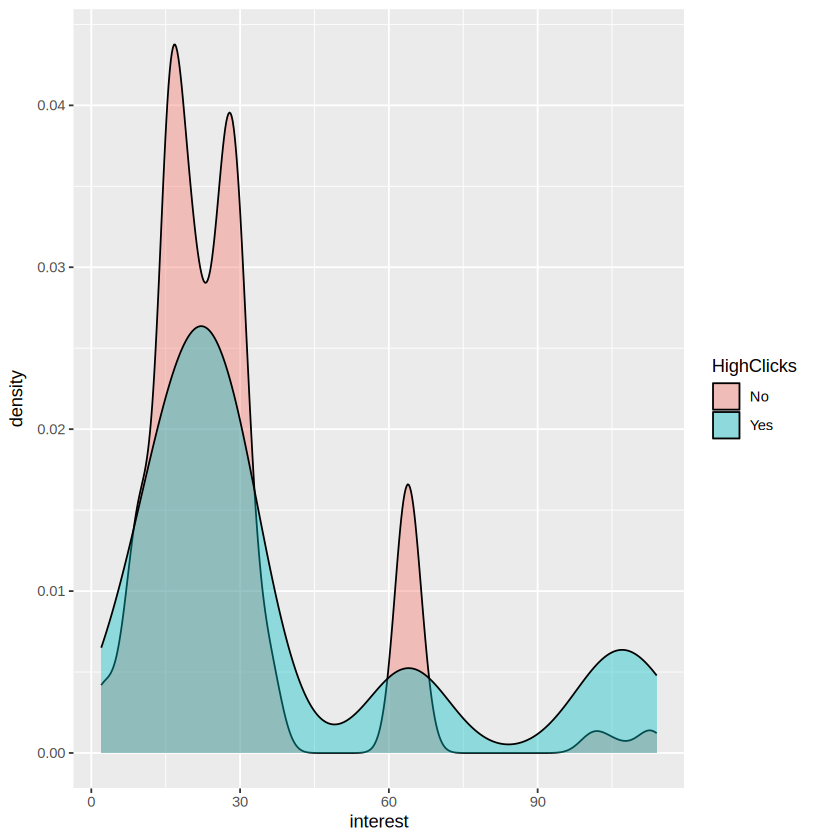

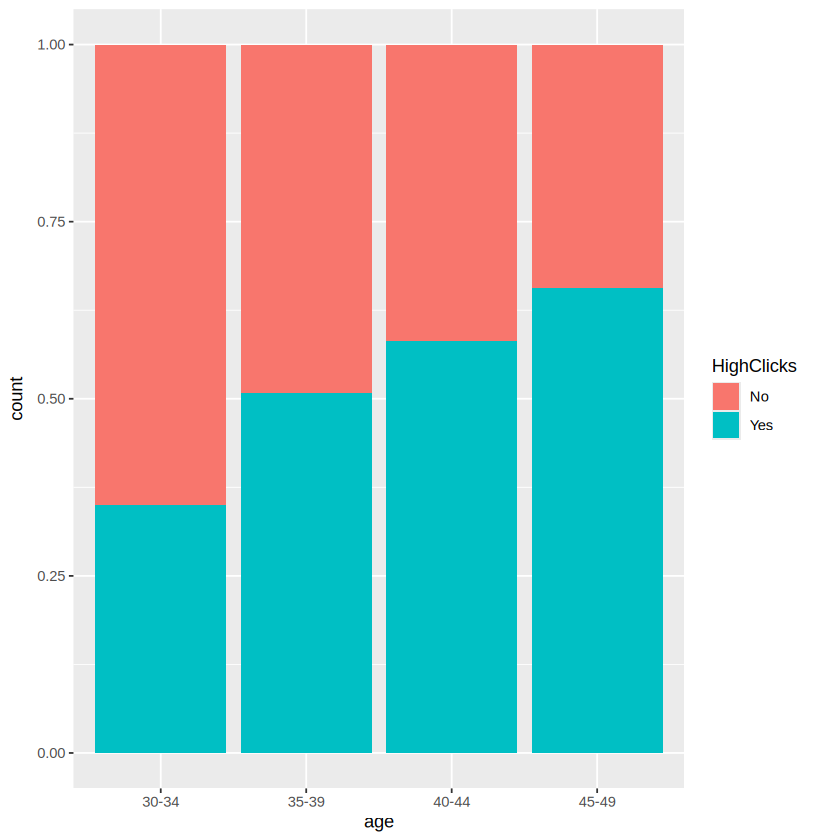

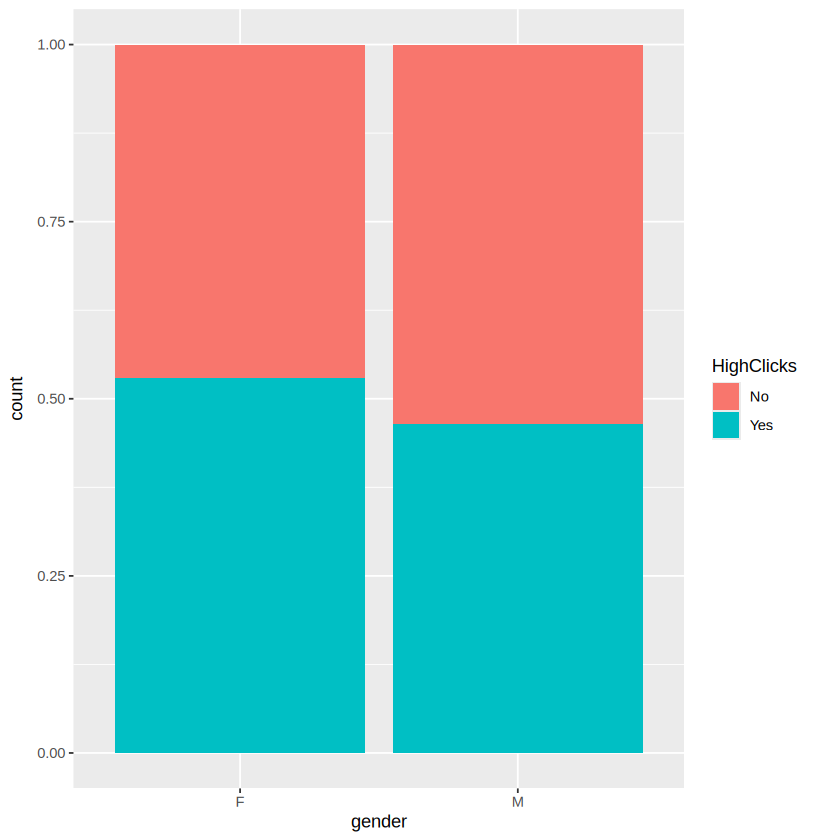

In [ ]:
library(ggplot2)
ggplot(kag, aes(x = interest, fill = HighClicks)) + geom_density(alpha = 0.4)
ggplot(kag, aes(x = age, fill = HighClicks)) + geom_bar(position = "fill")
ggplot(kag, aes(x = gender, fill = HighClicks)) + geom_bar(position = "fill")

In [ ]:
glm.fits <- glm(HighClicks ~ age + gender + interest,
                data = kag, family = binomial)
summary(glm.fits)


Call:
glm(formula = HighClicks ~ age + gender + interest, family = binomial, 
    data = kag)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) -1.021076   0.148116  -6.894 5.43e-12 ***
age35-39     0.636806   0.166280   3.830 0.000128 ***
age40-44     0.926112   0.176815   5.238 1.63e-07 ***
age45-49     1.263385   0.168862   7.482 7.33e-14 ***
genderM     -0.193990   0.124933  -1.553 0.120482    
interest     0.015902   0.002549   6.238 4.42e-10 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 1584.5  on 1142  degrees of freedom
Residual deviance: 1467.3  on 1137  degrees of freedom
AIC: 1479.3

Number of Fisher Scoring iterations: 4


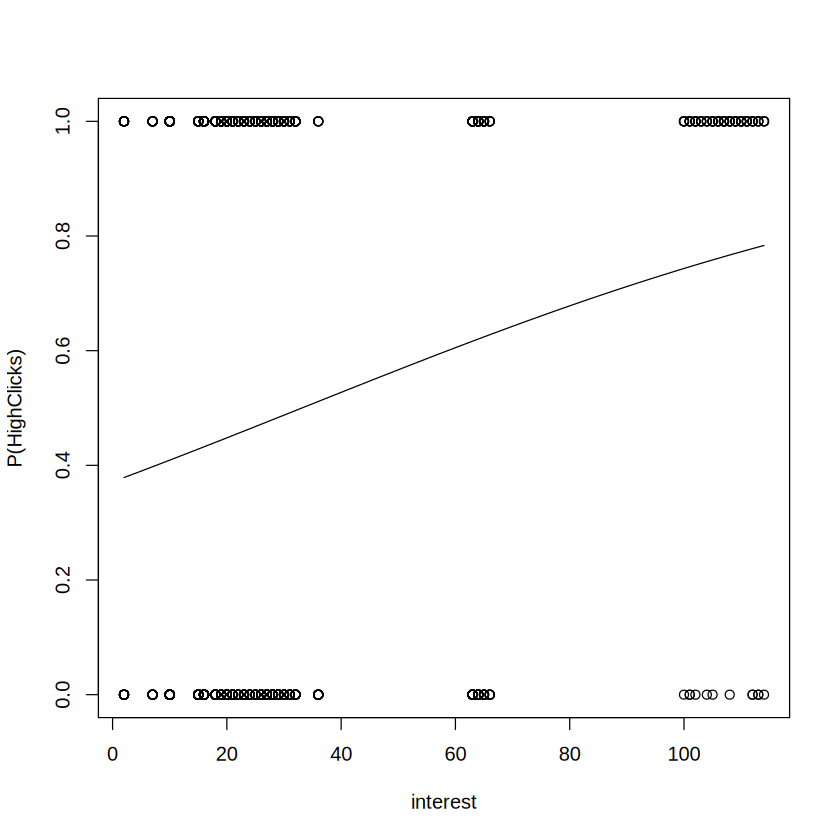

In [ ]:
fit1 <- glm(HighClicks ~ interest, data = kag, family = binomial)
plot(kag$interest, as.numeric(kag$HighClicks) - 1,
     xlab = "interest", ylab = "P(HighClicks)")
curve(predict(fit1, data.frame(interest = x), type = "response"), add = TRUE)

# Task 2

In [ ]:
library(MASS)

**Summary**

For the linear discriminant analysis and comparing it to logistic regression, I can see very little accuracy improvement, but there is some. For the linear discriminant model, the two class distributions are not exactly bell curves and do overlap some, but the no class has some identifying features that the yes class doesn’t. So there is some predictive capability here, looking at the output from the linear discriminant analysis. For the logistic regression, the accuracy is about 1% lower.

In [ ]:
lda.fit <- lda(HighClicks ~ age + gender + interest, data = kag)

In [ ]:
lda.fit

Call:
lda(HighClicks ~ age + gender + interest, data = kag)

Prior probabilities of groups:
      No      Yes 
0.503937 0.496063 

Group means:
     age35-39  age40-44  age45-49   genderM interest
No  0.2118056 0.1527778 0.1545139 0.5503472 27.43750
Yes 0.2222222 0.2151675 0.2998236 0.4850088 38.17989

Coefficients of linear discriminants:
                LD1
age35-39  1.0013462
age40-44  1.4580787
age45-49  1.9788374
genderM  -0.2975626
interest  0.0232047

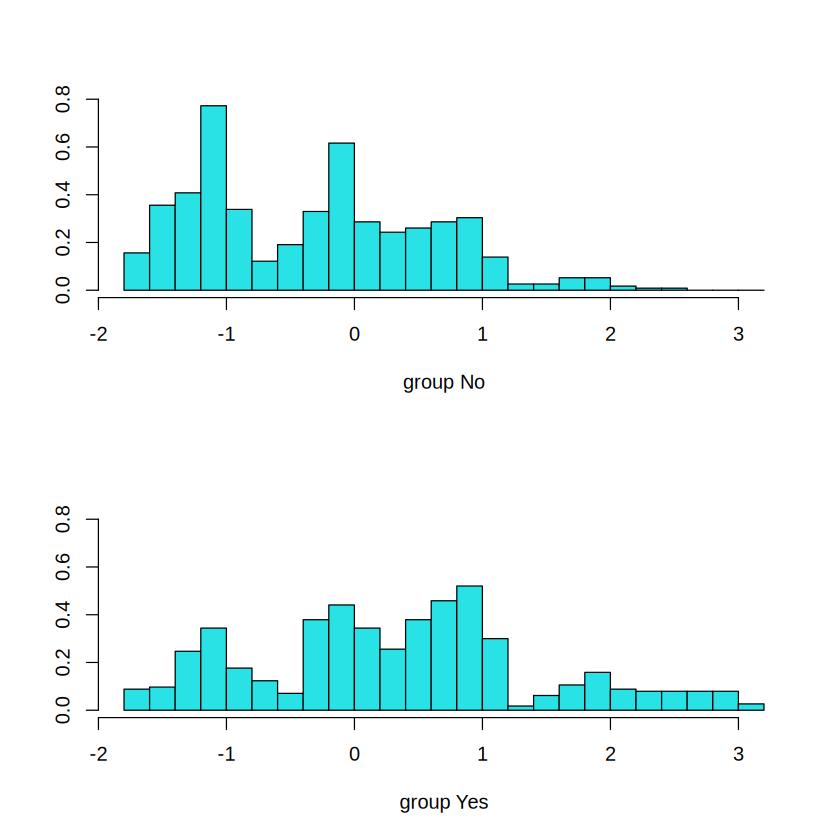

In [ ]:
plot(lda.fit)

In [ ]:
lda.pred <- predict(lda.fit, kag)
head(lda.pred$class)
head(lda.pred$posterior)

[1] No No No No No No
Levels: No Yes

,No,Yes
1,0.7304445,0.2695555
2,0.7274291,0.2725709
3,0.7151592,0.2848408
4,0.6896510,0.3103490
5,0.6896510,0.3103490
6,0.6863752,0.3136248


In [ ]:
table(lda.pred$class, kag$HighClicks)
mean(lda.pred$class == kag$HighClicks)

     
       No Yes
  No  379 225
  Yes 197 342

[1] 0.6307962

In [ ]:
glm.probs <- predict(glm.fits, type = "response")
glm.pred  <- ifelse(glm.probs > 0.5, "Yes", "No")
table(glm.pred, kag$HighClicks)
mean(glm.pred == kag$HighClicks)

        
glm.pred  No Yes
     No  375 224
     Yes 201 343

[1] 0.6281715

In [ ]:
str(kag[, c("HighClicks", "age", "gender", "interest")])
table(kag$HighClicks)

'data.frame':	1143 obs. of  4 variables:
 $ HighClicks: Factor w/ 2 levels "No","Yes": 1 1 1 1 1 1 1 1 1 1 ...
 $ age       : Factor w/ 4 levels "30-34","35-39",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ gender    : Factor w/ 2 levels "F","M": 2 2 2 2 2 2 2 2 2 2 ...
 $ interest  : int  15 16 20 28 28 29 15 16 27 28 ...



 No Yes 
576 567 

In [ ]:
set.seed(42)
n <- nrow(kag)
train_idx <- sample(1:n, size = round(0.8 * n))
train <- kag[train_idx, ]
test  <- kag[-train_idx, ]

c(train = nrow(train), test = nrow(test))
prop.table(table(train$HighClicks))

train  test 
  914   229


       No       Yes 
0.4890591 0.5109409 

In [ ]:
lda.train <- lda(HighClicks ~ age + gender + interest, data = train)
lda.train

Call:
lda(HighClicks ~ age + gender + interest, data = train)

Prior probabilities of groups:
       No       Yes 
0.4890591 0.5109409 

Group means:
     age35-39  age40-44  age45-49   genderM interest
No  0.2080537 0.1454139 0.1565996 0.5369128 27.72931
Yes 0.2205567 0.2098501 0.3040685 0.4732334 37.83512

Coefficients of linear discriminants:
                 LD1
age35-39  1.08620023
age40-44  1.52887473
age45-49  2.01038446
genderM  -0.33161146
interest  0.02188152

In [ ]:
lda.test.pred <- predict(lda.train, newdata = test)
table(Predicted = lda.test.pred$class, Actual = test$HighClicks)
mean(lda.test.pred$class == test$HighClicks)

         Actual
Predicted No Yes
      No  69  36
      Yes 60  64

[1] 0.580786

In [ ]:
set.seed(42)
k <- 10
folds <- sample(rep(1:k, length.out = nrow(kag)))

In [ ]:
fold_acc <- numeric(k)
for (i in 1:k) {
  tr <- kag[folds != i, ]
  te <- kag[folds == i, ]
  fit <- lda(HighClicks ~ age + gender + interest, data = tr)
  pred <- predict(fit, newdata = te)$class
  fold_acc[i] <- mean(pred == te$HighClicks)
}

In [ ]:
round(fold_acc, 4)
mean(fold_acc)


[1] 0.6957 0.5826 0.6000 0.5702 0.6404 0.6140 0.5789 0.5965 0.6140 0.6404

[1] 0.6132647

In [ ]:
data.frame(
  method   = c("80/20 split", "10-fold CV"),
  accuracy = c(mean(lda.test.pred$class == test$HighClicks), mean(fold_acc))
)

method,accuracy
<chr>,<dbl>
80/20 split,0.5807860
10-fold CV,0.6132647


**1.**

For the performance assessment of the k-fold model, the accuracy of the 80-20 split, 58%, is still above the baseline of guessing the positive class. But it is a much smaller isolation of data to use as a test, whereas the 10-fold cross-validation has 10 different splits, so its accuracy is more trustworthy. The 61% is 11 percentage points higher than the baseline. That is the model I would use, based on the results of the k-fold analysis.

**2.**

For the properties or limitations of my data set, I feel there are many shortcomings, a lot of them to do with my chosen target variable. I wanted to choose a target variable that was unconventional and not an obvious one, so I chose clicks, to see which predictors would show the likelihood of high clicks for the ads. With that choice, I had limited features, meaning variables I could include as predictors that I knew would work, such as gender, age and interest.

For the interest feature, I assumed the encoding was linear, but those values could be categorical, and that mapping could introduce noise. The LDA distributions that were plotted don’t look Gaussian; they look bimodal. I know one of the assumptions of LDA is that each class has a Gaussian distribution, so that probably cost some accuracy.

With k-fold, I think I did a good job of handling the limited sample size and the small amount of evaluation data, with just 20% of 1,143 rows. I don’t think this is a great model, though, because a lot of the LD1 class means are near each other. There isn’t much separation between the classes I chose for the features I chose, and that overlap will always cap the accuracy.